In [93]:
import pandas as pd
import matplotlib.pylab as plt
path = "images/"

In [94]:
hour_ds = pd.read_csv("data/hour.csv")
hour_ds = hour_ds.drop(columns=["instant"])
print(hour_ds.columns)
day_ds = pd.read_csv("data/day.csv")
print(day_ds.shape)

Index(['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='str')
(731, 16)


In [95]:
hour_ds.head()
hour_ds.tail()
print(hour_ds.info())
print(hour_ds.duplicated().sum())
print(hour_ds.isna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   dteday      17379 non-null  str    
 1   season      17379 non-null  int64  
 2   yr          17379 non-null  int64  
 3   mnth        17379 non-null  int64  
 4   hr          17379 non-null  int64  
 5   holiday     17379 non-null  int64  
 6   weekday     17379 non-null  int64  
 7   workingday  17379 non-null  int64  
 8   weathersit  17379 non-null  int64  
 9   temp        17379 non-null  float64
 10  atemp       17379 non-null  float64
 11  hum         17379 non-null  float64
 12  windspeed   17379 non-null  float64
 13  casual      17379 non-null  int64  
 14  registered  17379 non-null  int64  
 15  cnt         17379 non-null  int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 2.1 MB
None
0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
we

In [96]:
hour_ds['dteday'] = pd.to_datetime(hour_ds['dteday'])
print(hour_ds['dteday'].dtype)

datetime64[us]


In [97]:
columns = ["temp", "atemp","hum","windspeed","casual","registered","cnt"]

for clm in columns:
    print("The record of ", clm)
    print("Minimum Count is: ", hour_ds[clm].min())
    print("Maximum Count is: ", hour_ds[clm].max())

The record of  temp
Minimum Count is:  0.02
Maximum Count is:  1.0
The record of  atemp
Minimum Count is:  0.0
Maximum Count is:  1.0
The record of  hum
Minimum Count is:  0.0
Maximum Count is:  1.0
The record of  windspeed
Minimum Count is:  0.0
Maximum Count is:  0.8507
The record of  casual
Minimum Count is:  0
Maximum Count is:  367
The record of  registered
Minimum Count is:  0
Maximum Count is:  886
The record of  cnt
Minimum Count is:  1
Maximum Count is:  977


In [98]:
# Categorical data

hour_ds.columns
categorical_data = ['season', 'yr', 'mnth', 'hr',
    'holiday', 'weekday', 'workingday', 'weathersit']

for cat_data in categorical_data:
    print(f"The results of {cat_data}:")
    print(hour_ds[cat_data].value_counts().sort_index())

The results of season:
season
1    4242
2    4409
3    4496
4    4232
Name: count, dtype: int64
The results of yr:
yr
0    8645
1    8734
Name: count, dtype: int64
The results of mnth:
mnth
1     1429
2     1341
3     1473
4     1437
5     1488
6     1440
7     1488
8     1475
9     1437
10    1451
11    1437
12    1483
Name: count, dtype: int64
The results of hr:
hr
0     726
1     724
2     715
3     697
4     697
5     717
6     725
7     727
8     727
9     727
10    727
11    727
12    728
13    729
14    729
15    729
16    730
17    730
18    728
19    728
20    728
21    728
22    728
23    728
Name: count, dtype: int64
The results of holiday:
holiday
0    16879
1      500
Name: count, dtype: int64
The results of weekday:
weekday
0    2502
1    2479
2    2453
3    2475
4    2471
5    2487
6    2512
Name: count, dtype: int64
The results of workingday:
workingday
0     5514
1    11865
Name: count, dtype: int64
The results of weathersit:
weathersit
1    11413
2     4544
3     1419

In [99]:
avg_cnt = hour_ds.groupby("hr")["cnt"].mean().reset_index()
max_agCnt = avg_cnt["cnt"].max()
print(avg_cnt)
print(f"Maximum Average Count is {max_agCnt}.")
print(hour_ds["hr"].shape, avg_cnt['cnt'].shape)

    hr         cnt
0    0   53.898072
1    1   33.375691
2    2   22.869930
3    3   11.727403
4    4    6.352941
5    5   19.889819
6    6   76.044138
7    7  212.064649
8    8  359.011004
9    9  219.309491
10  10  173.668501
11  11  208.143054
12  12  253.315934
13  13  253.661180
14  14  240.949246
15  15  251.233196
16  16  311.983562
17  17  461.452055
18  18  425.510989
19  19  311.523352
20  20  226.030220
21  21  172.314560
22  22  131.335165
23  23   87.831044
Maximum Average Count is 461.45205479452056.
(17379,) (24,)


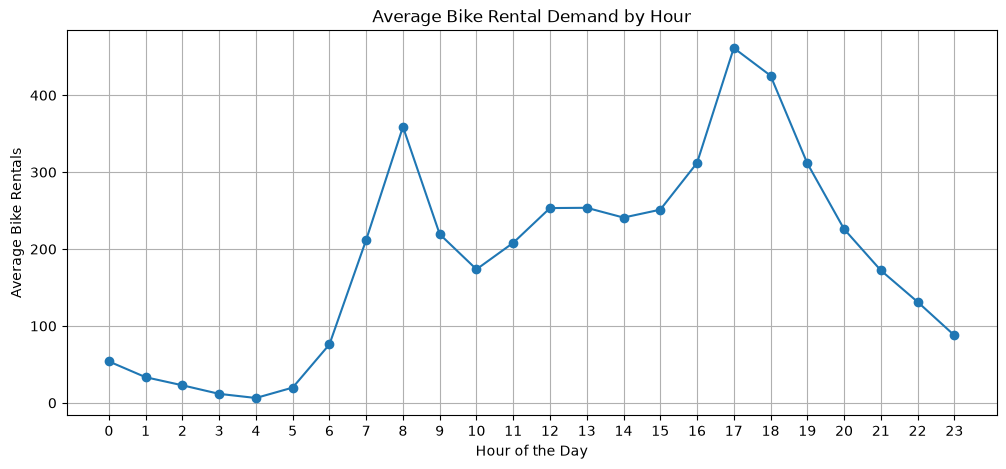

In [100]:
plt.figure(figsize=(12, 5))
plt.plot(avg_cnt["hr"], avg_cnt["cnt"], marker="o")

plt.xlabel("Hour of the Day")
plt.ylabel("Average Bike Rentals")
plt.title("Average Bike Rental Demand by Hour")
plt.xticks(range(24))
plt.grid(True)
plt.savefig(f"{path}01_hourly_bike_rental_demand.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

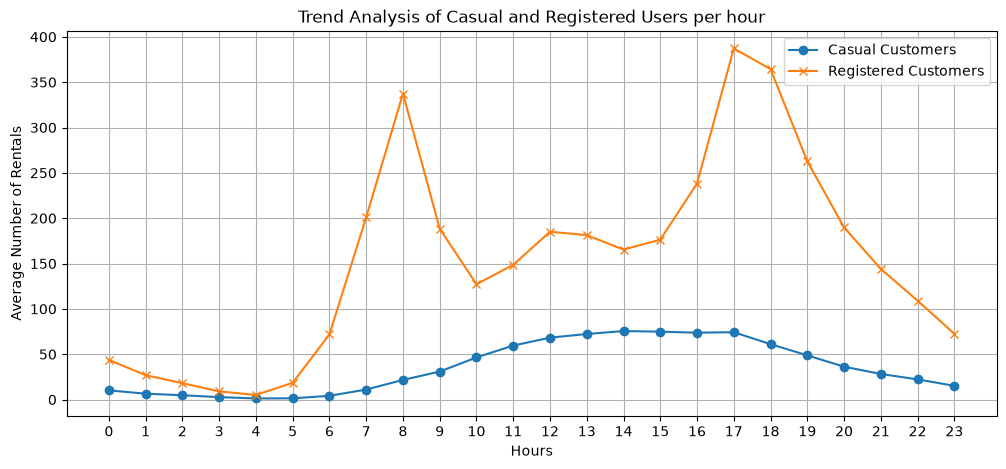

In [101]:
casual_hour = hour_ds.groupby("hr")["casual"].mean().reset_index()
regi_hour = hour_ds.groupby("hr")["registered"].mean().reset_index()

plt.figure(figsize=(12,5))
plt.plot(casual_hour["hr"],casual_hour["casual"], marker="o")
plt.plot(regi_hour["hr"],regi_hour["registered"], marker="x")
plt.xlabel("Hours")
plt.ylabel("Average Number of Rentals")
plt.title("Trend Analysis of Casual and Registered Users per hour")
plt.xticks(range(24))
plt.grid(True)
plt.legend(["Casual Customers", "Registered Customers"])
plt.savefig(f"{path}02_casual_vs_registered_demand.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

In [102]:
weekends_df = hour_ds[hour_ds["workingday"] == 0]
weekdays_df = hour_ds[hour_ds["workingday"] == 1]

weekendAvg = weekends_df.groupby("hr")["cnt"].mean()
weekdayAvg = weekdays_df.groupby("hr")["cnt"].mean()

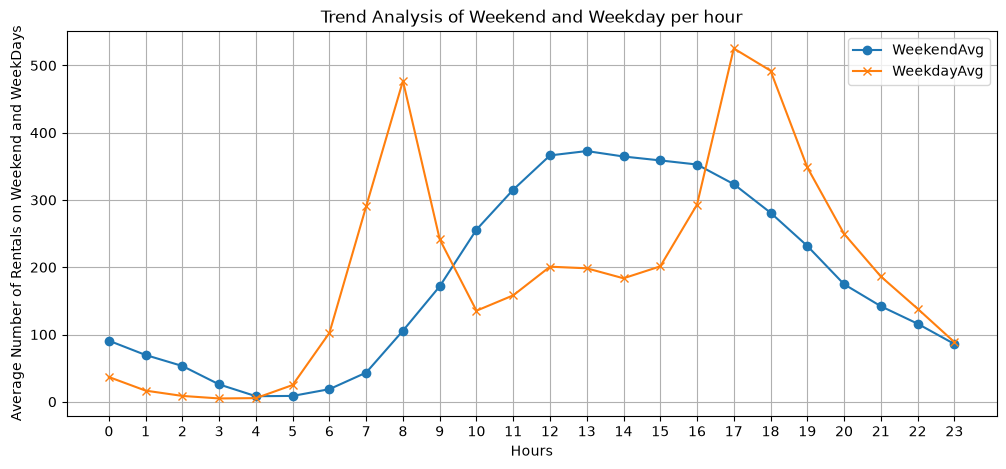

In [103]:
plt.figure(figsize=(12,5))
plt.plot(
    weekendAvg.index,
    weekendAvg.values,
    marker="o",
    label="Weekend"
)
plt.plot(
    weekdayAvg.index,
    weekdayAvg.values,
    marker="x",
    label="Weekday"
)
plt.legend(["WeekendAvg","WeekdayAvg"])
plt.xlabel("Hours")
plt.ylabel("Average Number of Rentals on Weekend and WeekDays")
plt.title("Trend Analysis of Weekend and Weekday per hour")
plt.xticks(range(24))
plt.grid(True)
plt.savefig(f"{path}03_weekday_vs_weekend_demand.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

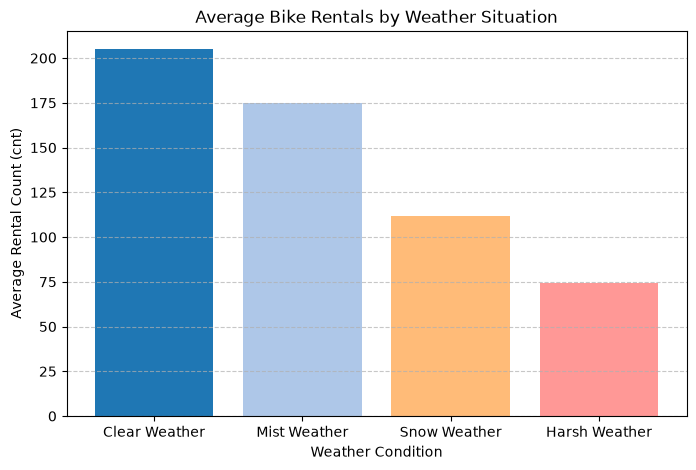

In [104]:
clrWeather = hour_ds[hour_ds["weathersit"] == 1].groupby("hr")["cnt"].mean()
mistWeather = hour_ds[hour_ds["weathersit"] == 2].groupby("hr")["cnt"].mean()
snowWeather = hour_ds[hour_ds["weathersit"] == 3].groupby("hr")["cnt"].mean()
harshWeather = hour_ds[hour_ds["weathersit"] == 4].groupby("hr")["cnt"].mean()

weather_avg = hour_ds.groupby("weathersit")["cnt"].mean()
weather_labels = ["Clear Weather", "Mist Weather", "Snow Weather", "Harsh Weather"]
plt.figure(figsize=(8, 5))
plt.bar(weather_labels, weather_avg.values, color=['#1f77b4', '#aec7e8', '#ffbb78', '#ff9896'])
plt.title("Average Bike Rentals by Weather Situation")
plt.xlabel("Weather Condition")
plt.ylabel("Average Rental Count (cnt)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig(f"{path}05_average_rentals_by_weather.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

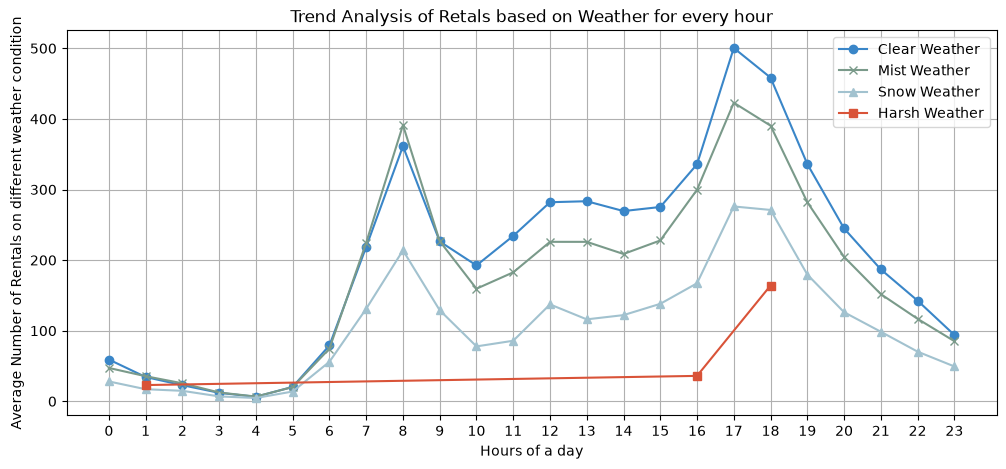

In [105]:
plt.figure(figsize=(12,5))
plt.plot(clrWeather.index,
         clrWeather.values,
         color="#3A86C8",
         marker="o",
        label="Clear Weather")
plt.plot(mistWeather.index,
        mistWeather.values,
        color="#7A9A8A",
        marker="x",
        label="Mist Weather")
plt.plot(snowWeather.index,
        snowWeather.values,
        color="#A2C2CF",
        marker="^",
        label="Snow Weather")
plt.plot(harshWeather.index,
        harshWeather.values,
        color="#D95338",
        marker="s",
        label="Harsh Weather")
plt.legend(["Clear Weather","Mist Weather","Snow Weather","Harsh Weather"])
plt.xlabel("Hours of a day")
plt.ylabel("Average Number of Rentals on different weather condition")
plt.title("Trend Analysis of Retals based on Weather for every hour")
plt.xticks(range(24))
plt.grid(True)
plt.savefig(f"{path}04_hourly_demand_by_weather.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()


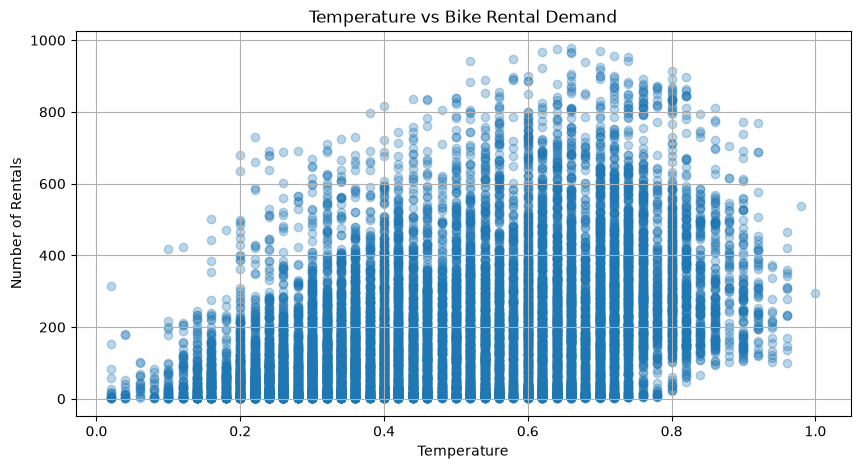

In [106]:
hour_ds[["temp","atemp","cnt"]].corr()
plt.figure(figsize=(10, 5))

plt.scatter(hour_ds["temp"], hour_ds["cnt"], alpha=0.3)

plt.xlabel("Temperature")
plt.ylabel("Number of Rentals")
plt.title("Temperature vs Bike Rental Demand")
plt.savefig(f"{path}06_temperature_vs_rental_demand.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.grid(True)
plt.show()

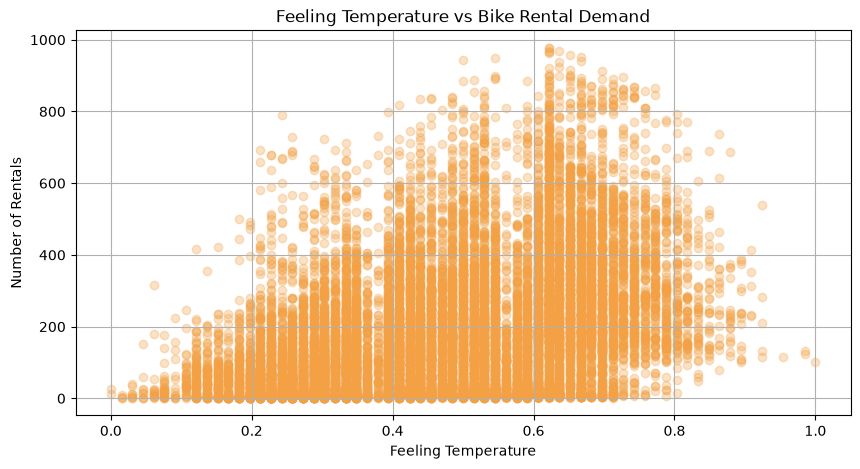

In [107]:
plt.figure(figsize=(10, 5))

plt.scatter(hour_ds["atemp"], hour_ds["cnt"], alpha=0.3,color="#f3a144")
plt.xlabel("Feeling Temperature")
plt.ylabel("Number of Rentals")
plt.title("Feeling Temperature vs Bike Rental Demand")
plt.savefig(f"{path}07_feels_like_temperature_vs_demand.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.grid(True)
plt.show()

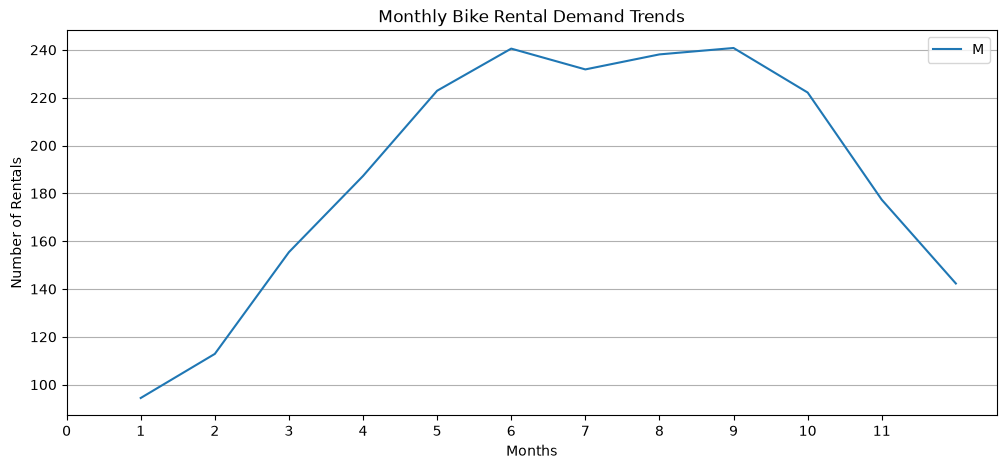

In [108]:
monthData = hour_ds.groupby("mnth")["cnt"].mean()
plt.figure(figsize=(12,5))
plt.plot(monthData.index,monthData.values)
plt.xlabel("Months")
plt.ylabel("Number of Rentals")
plt.title("Monthly Bike Rental Demand Trends")
plt.xticks(range(12))
plt.legend("Months")
plt.grid(axis="y")
plt.savefig(f"{path}12_Average_Bike_Rental_Demand_by_Months.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

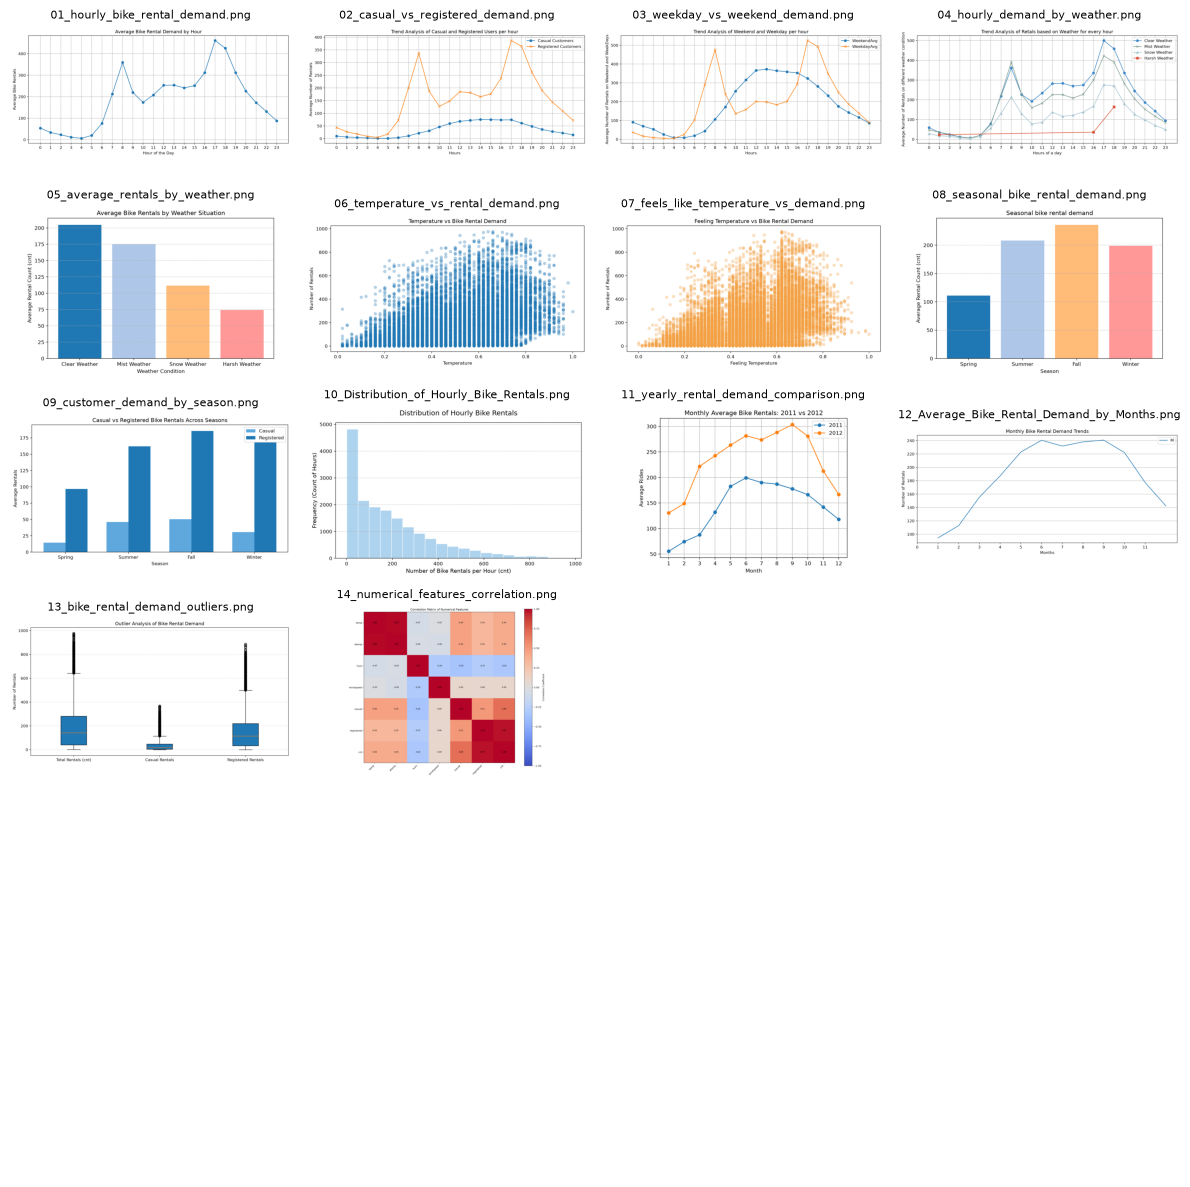

In [135]:
import math
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import numpy as np

# 1. Set the folder path and gather image files
folder_path = Path("images/")
image_extensions = ("*.jpg", "*.jpeg", "*.png", "*.bmp")
image_paths = sorted([
    p for ext in image_extensions 
    for p in folder_path.glob(ext)
])

num_images = len(image_paths)
if num_images == 0:
    raise ValueError(f"No images found in '{folder_path}'.")

# 2. Calculate grid dimensions (roughly square)
cols = math.ceil(math.sqrt(num_images))
rows = math.ceil(num_images / cols)

# 3. Create subplots and convert axes to a 1D NumPy array
fig, axes = plt.subplots(rows+2, cols, figsize=(12, 12))
axes = np.atleast_1d(axes).flatten()

# 4. Read and plot each image
for i, img_path in enumerate(image_paths):
    img = mpimg.imread(str(img_path))
    axes[i].imshow(img)
    axes[i].set_title(img_path.name, fontsize=8)
    axes[i].axis("off")

# 5. Hide any remaining empty subplot frames
for j in range(num_images, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()


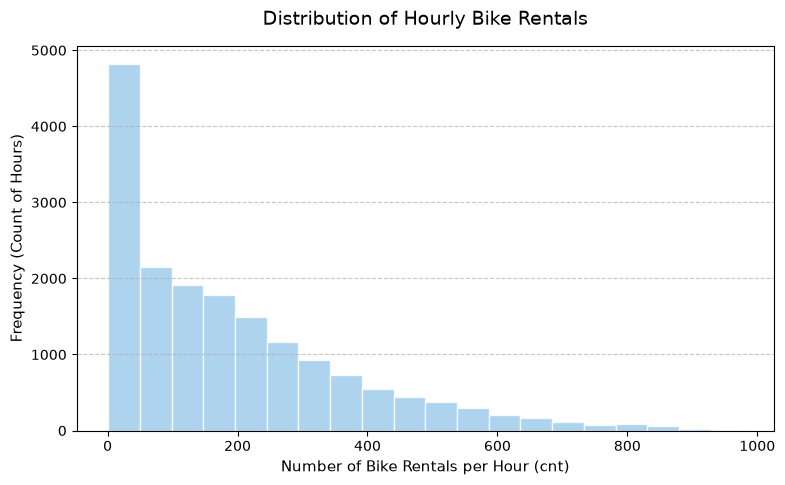

In [116]:
plt.figure(figsize=(9, 5))
plt.hist(hour_ds["cnt"], bins=20, edgecolor="white", color="#99c8ea", alpha=0.8)
plt.title("Distribution of Hourly Bike Rentals", fontsize=14, pad=15)
plt.xlabel("Number of Bike Rentals per Hour (cnt)", fontsize=11)
plt.ylabel("Frequency (Count of Hours)", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.savefig(f"{path}10_Distribution_of_Hourly_Bike_Rentals.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()


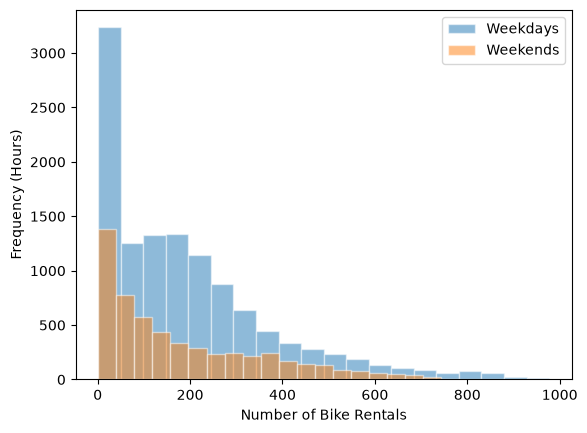

In [111]:
plt.hist(hour_ds[hour_ds["workingday"] == 1]["cnt"], bins=20, alpha=0.5, label="Weekdays",edgecolor="#ffffff")
plt.hist(hour_ds[hour_ds["workingday"] == 0]["cnt"], bins=20, alpha=0.5, label="Weekends",edgecolor="#ffffff")
plt.xlabel("Number of Bike Rentals")
plt.ylabel("Frequency (Hours)")
plt.legend()
plt.show()


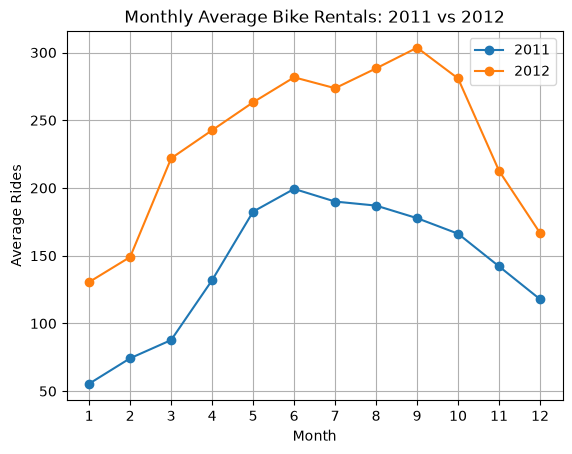

In [134]:
monthlyAvg = hour_ds.groupby(["yr","mnth"])["cnt"].mean().reset_index()
data_2011 = monthlyAvg[monthlyAvg["yr"] == 0]
data_2012 = monthlyAvg[monthlyAvg["yr"] == 1]
plt.plot(
    data_2011["mnth"],
    data_2011["cnt"],
    label="2011",
    marker="o",
)
plt.plot(
    data_2012["mnth"],
    data_2012["cnt"],
    label="2012",
    marker="o",
)
plt.title("Monthly Average Bike Rentals: 2011 vs 2012")
plt.xlabel("Month")
plt.ylabel("Average Rides")
plt.xticks(range(1, 13))
plt.legend()
plt.grid(True)
plt.savefig(f"{path}11_yearly_rental_demand_comparison.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

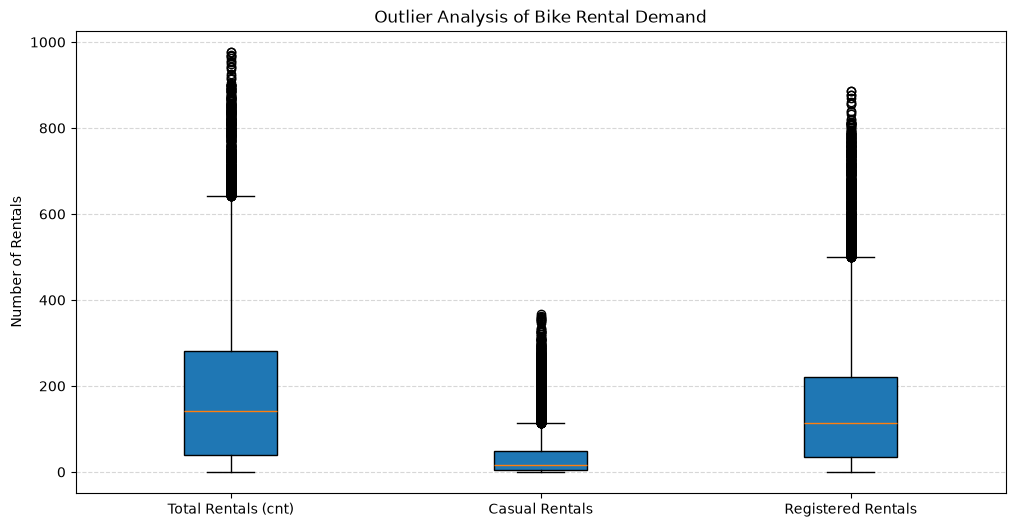

In [113]:
plt.figure(figsize=(12, 6))
plt.boxplot(
    [hour_ds["cnt"], hour_ds["casual"], hour_ds["registered"]],
    tick_labels=["Total Rentals (cnt)", "Casual Rentals", "Registered Rentals"],
    patch_artist=True
)
plt.title("Outlier Analysis of Bike Rental Demand")
plt.ylabel("Number of Rentals")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.savefig(f"{path}13_bike_rental_demand_outliers.png",
            dpi=200, bbox_inches="tight")
plt.show()

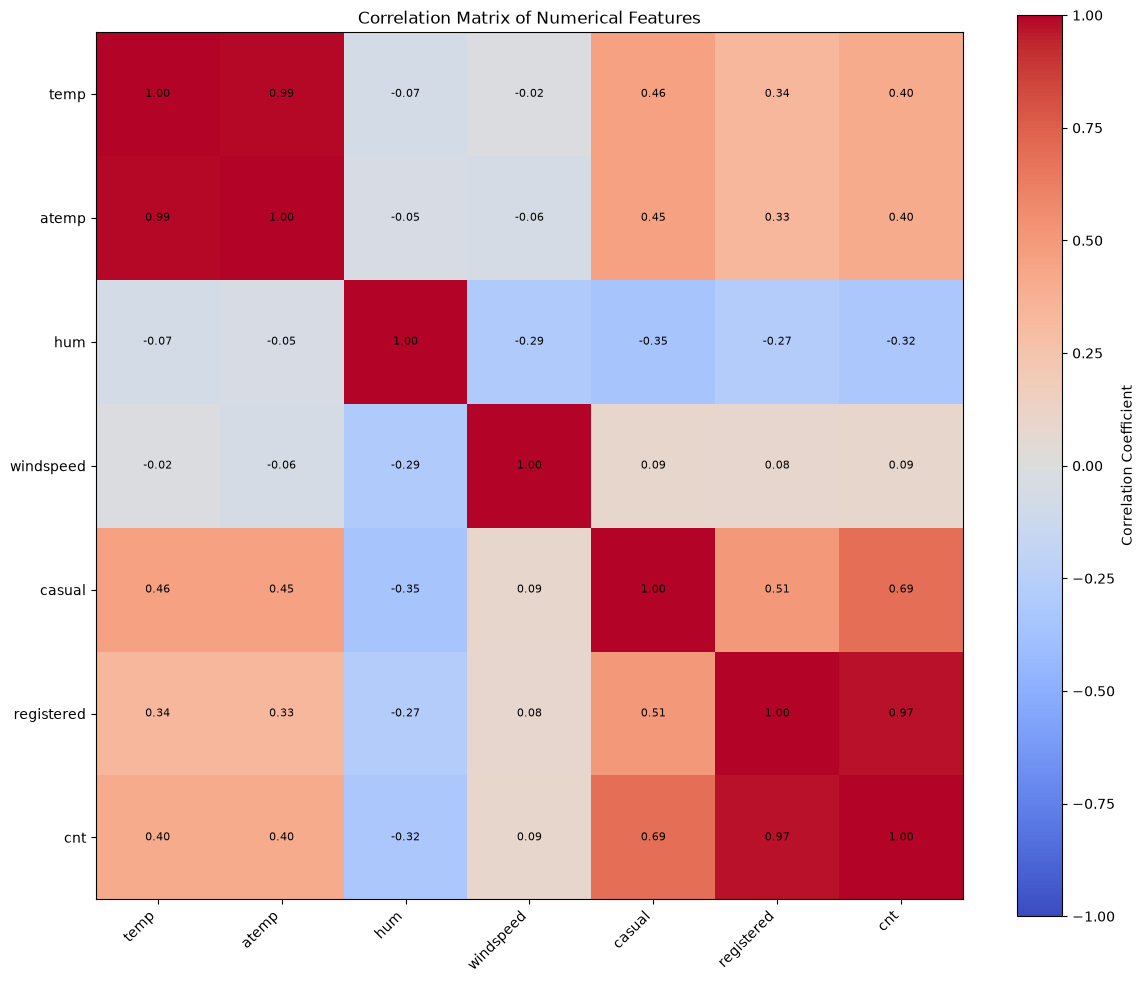

In [114]:
corr_cols = [
    "temp",
    "atemp",
    "hum",
    "windspeed",
    "casual",
    "registered",
    "cnt"
]

corr_matrix = hour_ds[corr_cols].corr()
plt.figure(figsize=(12, 10))
plt.imshow(corr_matrix, cmap="coolwarm", interpolation="nearest", vmin=-1, vmax=1)
plt.colorbar(label="Correlation Coefficient")
plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        plt.text(j, i, f"{corr_matrix.iloc[i, j]:.2f}",
                 ha="center", va="center", fontsize=8)
plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.savefig(f"{path}14_numerical_features_correlation.png",
            dpi=200, bbox_inches="tight")
plt.show()

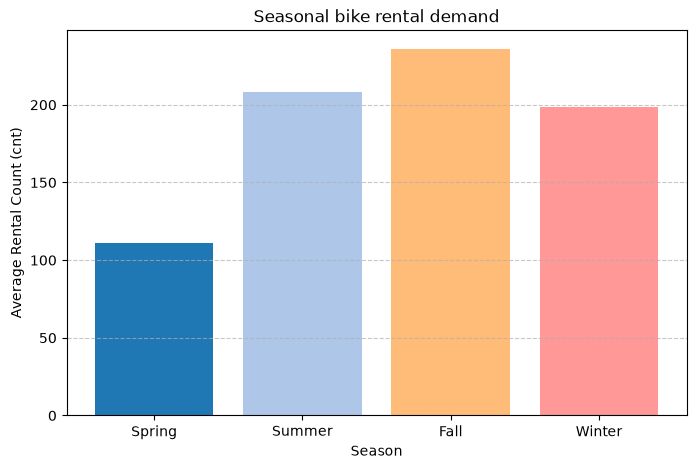

In [133]:
spring = hour_ds[hour_ds["season"] == 1].groupby("season")["cnt"].mean()
summer = hour_ds[hour_ds["season"] == 2].groupby("season")["cnt"].mean()
fall = hour_ds[hour_ds["season"] == 3].groupby("season")["cnt"].mean()
winter = hour_ds[hour_ds["season"] == 4].groupby("season")["cnt"].mean()

seasonalRides = hour_ds.groupby("season")["cnt"].mean()

season_labels = ["Spring", "Summer" ,"Fall", "Winter"]
plt.figure(figsize=(8, 5))
plt.bar(season_labels, seasonalRides.values, color=['#1f77b4', '#aec7e8', '#ffbb78', '#ff9896'])
plt.title("Seasonal bike rental demand")
plt.xlabel("Season")
plt.ylabel("Average Rental Count (cnt)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig(f"{path}08_seasonal_bike_rental_demand.png", 
    dpi=200,
    bbox_inches="tight",
    transparent=False)
plt.show()

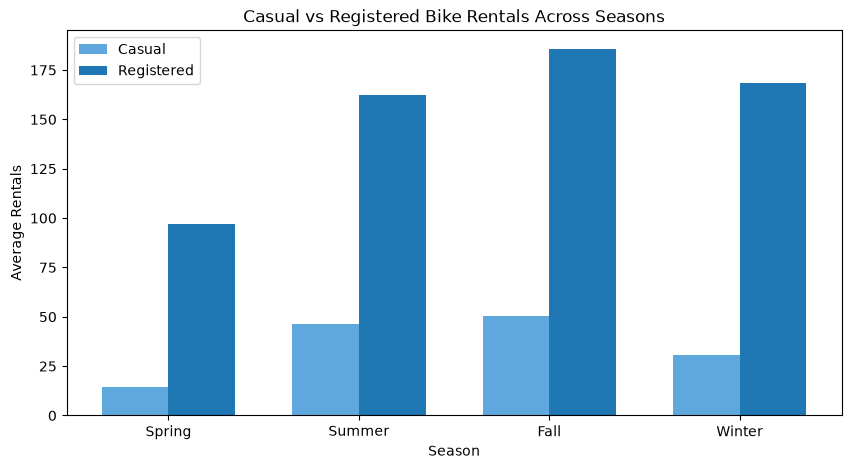

In [128]:
season_customer = hour_ds.groupby("season")[["casual", "registered"]].mean()
season_customer = season_customer.reindex([1, 2, 3, 4])
season_customer.index = ["Spring", "Summer", "Fall", "Winter"]

x = range(len(season_customer))
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar([i - width/2 for i in x],
        season_customer["casual"],
        width=width,
        label="Casual",color="#53a2dbee")

plt.bar([i + width/2 for i in x],
        season_customer["registered"],
        width=width,
        label="Registered")

plt.xticks(list(x), season_customer.index)

plt.title("Casual vs Registered Bike Rentals Across Seasons")
plt.xlabel("Season")
plt.ylabel("Average Rentals")
plt.legend()

plt.savefig(f"{path}09_customer_demand_by_season.png",
            dpi=200, bbox_inches="tight")

plt.show()